# The ten by ten benchmark of the analytic holograms

**Question:** Do the analytic baselines, the superposition, the random superposition and the random mask, reproduce the published 10 by 10 comparison once they run on DinHot's own grid, and what in the grid decides the answer?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 50 minutes

## Objectives

A baseline is useful only if it is known to be right. The paper that introduced the weighted algorithm printed a table of three analytic holograms on a 10 by 10 array, and that table is the yardstick of every later method. DinHot does not use the paper's 768 by 768 pixel SLM, it uses 256 by 256, so a difference from the table could be an error or a consequence of the grid. You will move the same array onto five SLM sizes, run the three methods on each, read the pixels per trap as the variable that matters, set the 768 by 768 result against the published numbers, and test two other explanations for the gaps: the beam and the 8-bit quantization of the paper's device.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. The next cell imports the tools, prints their versions and puts the pipeline on the path.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import importlib.metadata as md
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, metrics
from pipeline.model.holo.core.device import quantize
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import snap_to_bins
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.baseline import m01_superposition, m02_random_superposition, m03_random_mask

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def array_numbers(phi, setup, traps):
    """Efficiency, uniformity and relative spread (percent) of a hologram read with the point-trap form."""
    i = metrics.trap_intensities(forward.point_trap_fields(phi, setup, traps))
    return metrics.efficiency(i), metrics.uniformity(i), metrics.rel_std(i)

numpy 2.4.6
matplotlib 3.11.2


## Data

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot, for the array; the published values are those printed in Di Leonardo et al. 2007, Table 1, https://doi.org/10.1364/OE.15.001913.
- Licence class: synthetic case written by the product; the published numbers are quoted as facts with their source.
- File read: `data/examples/cases.json`, case C12, and three seeds counted up from its seed.

In [2]:
# case C12 gives the array; the published values of Di Leonardo et al. 2007 are the reference column
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C12_calibration"]
base_setup = setup_of(rec)
base_traps = target_of(rec).traps
published = {"M01": (0.29, 0.01, 257.0), "M02": (0.69, 0.01, 89.0), "M03": (0.01, 0.58, 16.0)}
budget = Budget(1)
seeds = [rec["seed"] + k for k in range(3)]
print(f"{len(base_traps)} traps, SLM {base_setup.n_pix} x {base_setup.n_pix}, {len(seeds)} seeds")

100 traps, SLM 256 x 256, 3 seeds


## Method

The three methods are those of the previous notebook, and the metrics are efficiency $e$, uniformity $u$ and relative spread $\sigma$ of topic 01. The published row is, for the superposition, $e = 0.29$, $u = 0.01$, $\sigma = 257$ percent; for the random superposition, $0.69$, $0.01$ and $89$ percent; for the random mask, $0.01$, $0.58$ and $16$ percent, all on 768 by 768 pixels with 8 bits (Di Leonardo et al. 2007, Table 1). The grid enters the physics in one place that matters here: the random mask gives each trap $N/M$ pixels and the rest of the pixels are noise on it, so its uniformity should improve with $N/M$ and its spread should follow $\sqrt{2}\,M/\sqrt{N}$ (notebook 01). The other two methods have no such dependence. The plan is to keep the array and the physical size of the SLM fixed and change only the number of pixels, which is exactly what `replace(setup, n_pix=n)` does, then to move each trap to the nearest bin of the new focal grid with `snap_to_bins`, because the bin size changes with $N$.

The first cell builds five setups, from 128 by 128 to 768 by 768 pixels, and moves the array to each focal grid. It prints the pixels per trap, which is the variable the argument uses, and the largest distance a trap had to move: if it is zero the array is the same array on every grid.

In [3]:
# the same array on five SLM sizes: the trap positions are moved to the nearest bin of each grid
sizes = [128, 256, 384, 512, 768]
grids = {}
for n in sizes:
    setup_n = replace(base_setup, n_pix=n)
    traps_n = snap_to_bins(setup_n, base_traps)
    shift_um = np.hypot(traps_n.x_m - base_traps.x_m, traps_n.y_m - base_traps.y_m).max() * 1e6
    grids[n] = (setup_n, Target.from_traps(traps_n))
    print(f"{n} x {n}: {n * n / len(traps_n):5.0f} pixels per trap")
    print(f"        largest trap shift to the grid: {shift_um:.3f} um")

128 x 128:   164 pixels per trap
        largest trap shift to the grid: 0.000 um
256 x 256:   655 pixels per trap
        largest trap shift to the grid: 0.000 um
384 x 384:  1475 pixels per trap
        largest trap shift to the grid: 0.000 um
512 x 512:  2621 pixels per trap
        largest trap shift to the grid: 0.000 um
768 x 768:  5898 pixels per trap
        largest trap shift to the grid: 0.000 um


The superposition is deterministic, so one run per grid is enough.

In [4]:
# M01 on every grid: one deterministic hologram per size
table = {"M01": {}, "M02": {}, "M03": {}}
for n, (setup_n, target_n) in grids.items():
    res = m01_superposition.run(setup_n, target_n, budget=budget, rng=Rng(seeds[0]))
    table["M01"][n] = np.array([array_numbers(res.phi, setup_n, target_n.traps)])
    e, u, sigma = table["M01"][n][0]
    print(f"M01 {n:3d}: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")

M01 128: e = 0.3248, u = 0.0002, sigma = 271.89 %
M01 256: e = 0.3280, u = 0.0003, sigma = 268.79 %
M01 384: e = 0.3286, u = 0.0003, sigma = 268.22 %
M01 512: e = 0.3288, u = 0.0003, sigma = 268.02 %
M01 768: e = 0.3290, u = 0.0003, sigma = 267.88 %


The random superposition runs with three seeds on each grid, and the cell prints the mean of the three numbers.

In [5]:
# M02 on every grid, the mean over the seeds
for n, (setup_n, target_n) in grids.items():
    runs = [m02_random_superposition.run(setup_n, target_n, budget=budget, rng=Rng(s)) for s in seeds]
    table["M02"][n] = np.array([array_numbers(r.phi, setup_n, target_n.traps) for r in runs])
    e, u, sigma = table["M02"][n].mean(axis=0)
    print(f"M02 {n:3d}: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")

M02 128: e = 0.7361, u = 0.1803, sigma = 40.78 %
M02 256: e = 0.7361, u = 0.1829, sigma = 40.66 %
M02 384: e = 0.7361, u = 0.1834, sigma = 40.64 %
M02 512: e = 0.7361, u = 0.1836, sigma = 40.63 %
M02 768: e = 0.7361, u = 0.1837, sigma = 40.63 %


The random mask is the expensive one, because each trap builds its own phase over the whole SLM; the cell runs three seeds on each grid and keeps the first hologram of the largest grid for the quantization test below.

In [6]:
# M03 on every grid, the mean over the seeds (the 768 x 768 grid takes the longest)
phases_768 = {}
for n, (setup_n, target_n) in grids.items():
    runs = [m03_random_mask.run(setup_n, target_n, budget=budget, rng=Rng(s)) for s in seeds]
    table["M03"][n] = np.array([array_numbers(r.phi, setup_n, target_n.traps) for r in runs])
    phases_768[n] = runs[0].phi
    e, u, sigma = table["M03"][n].mean(axis=0)
    print(f"M03 {n:3d}: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")

M03 128: e = 0.0153, u = 0.0017, sigma = 78.05 %
M03 256: e = 0.0101, u = 0.0628, sigma = 50.97 %
M03 384: e = 0.0094, u = 0.2649, sigma = 35.12 %
M03 512: e = 0.0091, u = 0.3387, sigma = 30.68 %
M03 768: e = 0.0089, u = 0.5472, sigma = 18.06 %


Now the published table. The cell prints, for each method, the published numbers and the mean of the measured ones on the 768 by 768 grid, and also the spread that the $1/\sqrt{N}$ law predicts for the random mask on that grid.

In [7]:
# the published row and the measured row on the largest grid, side by side
setup_big, target_big = grids[768]
for name, ref in published.items():
    e, u, sigma = table[name][768].mean(axis=0)
    print(f"{name} published: e = {ref[0]:.2f}, u = {ref[1]:.2f}, sigma = {ref[2]:.0f} %")
    print(f"{name} measured : e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")
predicted = 100.0 * np.sqrt(2.0) * len(base_traps) / 768
print(f"M03 predicted spread of the random mask at 768 x 768, 1 / sqrt(N) law: {predicted:.1f} %")

M01 published: e = 0.29, u = 0.01, sigma = 257 %
M01 measured : e = 0.3290, u = 0.0003, sigma = 267.88 %
M02 published: e = 0.69, u = 0.01, sigma = 89 %
M02 measured : e = 0.7361, u = 0.1837, sigma = 40.63 %
M03 published: e = 0.01, u = 0.58, sigma = 16 %
M03 measured : e = 0.0089, u = 0.5472, sigma = 18.06 %
M03 predicted spread of the random mask at 768 x 768, 1 / sqrt(N) law: 18.4 %


The random superposition does not change with the grid, so the gap to its published row needs another cause. One candidate is the beam: the product's default is Gaussian and a flat beam is uniform, and the paper does not state which it used. The cell reruns the random superposition on the largest grid with a flat beam.

In [8]:
# is the gap of M02 a matter of the beam? the same array with a flat beam instead of the Gaussian one
flat_setup = replace(setup_big, beam="flat")
flat_runs = [m02_random_superposition.run(flat_setup, target_big, budget=budget, rng=Rng(s)) for s in seeds]
flat = np.array([array_numbers(r.phi, flat_setup, target_big.traps) for r in flat_runs]).mean(axis=0)
print(f"Gaussian beam: e = {table['M02'][768].mean(axis=0)[0]:.4f}, u = {table['M02'][768].mean(axis=0)[1]:.4f}")
print(f"flat beam    : e = {flat[0]:.4f}, u = {flat[1]:.4f}, sigma = {flat[2]:.2f} %")

Gaussian beam: e = 0.7361, u = 0.1837
flat beam    : e = 0.8466, u = 0.1838, sigma = 40.63 %


Another candidate is the 8-bit SLM of the paper. The cell quantizes the 768 by 768 holograms of the random superposition and of the random mask to 8 bits with the device model and reads them again.

In [9]:
# the paper used 8 bits: quantize the 768 x 768 holograms of M03 and M02 and read them again
mask_768 = phases_768[768]
sr_768 = m02_random_superposition.run(setup_big, target_big, budget=budget, rng=Rng(seeds[0])).phi
for name, phi in (("M02", sr_768), ("M03", mask_768)):
    before = array_numbers(phi, setup_big, target_big.traps)
    after = array_numbers(quantize(phi, 8), setup_big, target_big.traps)
    print(f"{name}: ideal e = {before[0]:.4f}, u = {before[1]:.4f}; 8 bit e = {after[0]:.4f}, u = {after[1]:.4f}")

M02: ideal e = 0.7485, u = 0.1986; 8 bit e = 0.7485, u = 0.1979
M03: ideal e = 0.0089, u = 0.4991; 8 bit e = 0.0089, u = 0.4991


The first figure plots the three numbers against the pixels per trap on a logarithmic axis, with the published values on 768 by 768 as black stars at the right edge.

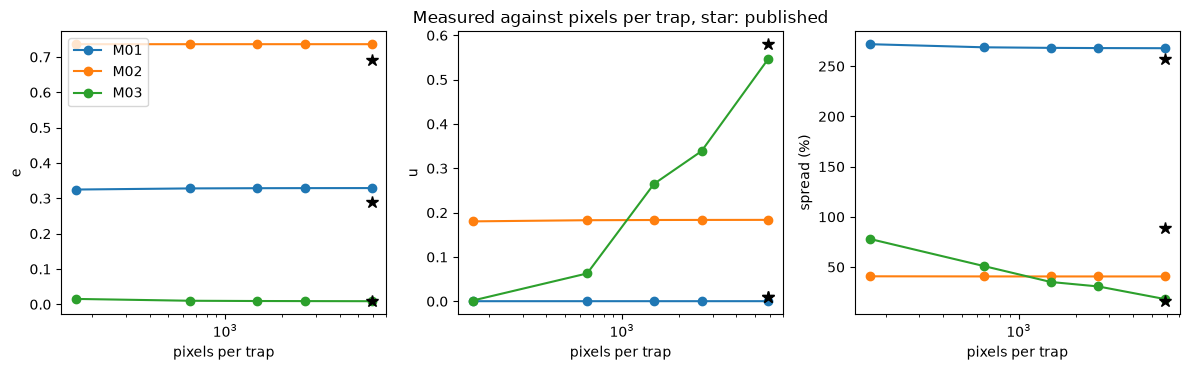

In [10]:
# the three numbers against the pixels per trap; stars are the published values on 768 x 768
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
ppt = [n * n / len(base_traps) for n in sizes]
for k, (ax, label) in enumerate(zip(axes, ("e", "u", "spread (%)"))):
    for name in table:
        ax.semilogx(ppt, [table[name][n].mean(axis=0)[k] for n in sizes], "o-", label=name)
        ax.semilogx(ppt[-1], published[name][k], "k*", ms=9)
    ax.set_xlabel("pixels per trap")
    ax.tick_params(axis="x", which="minor", labelbottom=False)
    ax.set_ylabel(label)
axes[1].set_title("Measured against pixels per trap, star: published")
axes[0].legend()
fig.tight_layout()
plt.show()

The superposition and the random superposition are flat lines: nothing in $e$, $u$ or $\sigma$ depends on the pixels per trap, so a larger SLM cannot change them. The random mask moves along its whole range: its uniformity rises from 0.0017 at 164 pixels per trap to 0.5472 at 5898, its spread falls from 78.05 to 18.06 percent, and its efficiency falls slowly from 0.0153 to 0.0089. At 5898 pixels per trap the random mask lands next to the stars, which the other two methods do not. The figure does not show the seed-to-seed variation; with three seeds the markers are means, and the next figure is read with that in mind.

The second figure shows the ratio of measured to published for each method and each number on the 768 by 768 grid, on a logarithmic axis where the line at 1 means that the number is reproduced.

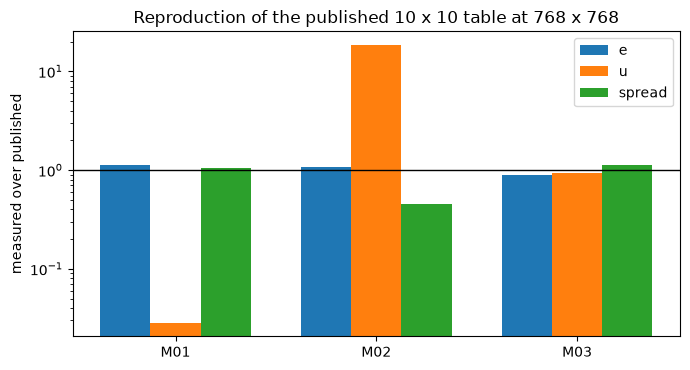

In [11]:
# measured over published, per method and per number, on the largest grid (1 means reproduced)
fig, ax = plt.subplots(figsize=(7, 3.8))
width = 0.25
for k, label in enumerate(("e", "u", "spread")):
    ratio = [table[name][768].mean(axis=0)[k] / published[name][k] for name in published]
    ax.bar(np.arange(3) + (k - 1) * width, ratio, width, label=label)
ax.set_yscale("log")
ax.axhline(1.0, color="k", lw=1)
ax.set_xticks(range(3), list(published))
ax.set_ylabel("measured over published")
ax.set_title("Reproduction of the published 10 x 10 table at 768 x 768")
ax.legend()
fig.tight_layout()
plt.show()

The random mask is within about 13 percent of the published row in all three numbers, and the superposition reproduces the efficiency and the spread within 13 percent, while its uniformity of 0.0003 is much below the published 0.01 (both are near zero: a uniformity under 0.01 says that the weakest trap is a hundredth of the brightest). The random superposition reproduces the efficiency to 7 percent but not the uniformity, which is 18 times the published value, nor the spread, which is 0.46 of the published one. Read on a log axis the figure makes the same point as the previous one, with one added fact: the discrepancy of the random superposition is not a matter of a few percent. The figure cannot say whether the paper's table used the same amplitude convention or a different set of random phases, and this notebook does not claim a cause for the gap.

## Results

**Answer:** The analytic baselines reproduce the published 10 by 10 comparison for two of the three methods: the superposition, and the random mask when the grid has the paper's pixels per trap; the random superposition does not. At 768 by 768 pixels, 5898 pixels per trap, the random mask measures $e = 0.0089$, $u = 0.5472$ and $\sigma = 18.06$ percent against the published 0.01, 0.58 and 16, and the law $\sqrt{2}\,M/\sqrt{N}$ predicts 18.4 percent; on DinHot's 256 by 256 grid, with 655 pixels per trap, it gives $u = 0.0628$ and $\sigma = 50.97$ percent, which is not a failure of the code but of the pixel count. The superposition measures $e = 0.3290$ and $\sigma = 267.88$ percent against 0.29 and 257, and its uniformity of 0.0003 is below the published 0.01. The random superposition does not reproduce the table: its $u = 0.1837$ and $\sigma = 40.63$ percent are the same at every grid size and with a flat beam ($e = 0.8466$, $u = 0.1838$), and the 8-bit quantization changes $u$ from 0.1986 to 0.1979, so neither the grid, the beam nor the bit depth explains the gap to the published 0.01 and 89 percent.

## Summary

Two of the three analytic baselines agree with the 2007 table, and the third differs in a way that no variable of this notebook explains: the random superposition is the open item, and it is reported as such. The practical consequence is for the later notebooks. On DinHot's 256 by 256 SLM the random mask is a poor baseline for a 100-trap array, because a trap owns 655 pixels; the weighted methods that follow are not limited by it in the same way, and topic 03 measures them on this array; they are measured against these three numbers on the same array.

## References

- Di Leonardo, Ianni and Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.